Shape: (178, 14)
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13 

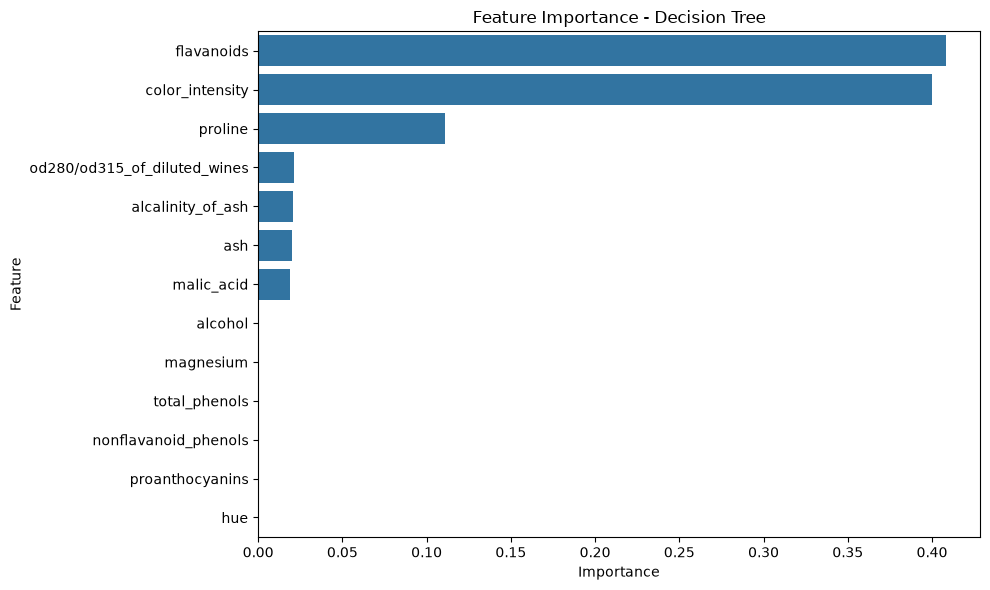

                         Feature  Importance
9                color_intensity    0.187580
6                     flavanoids    0.159561
12                       proline    0.146799
0                        alcohol    0.117913
10                           hue    0.101538
11  od280/od315_of_diluted_wines    0.096301
5                  total_phenols    0.041514
4                      magnesium    0.040131
1                     malic_acid    0.033894
3              alcalinity_of_ash    0.025471
8                proanthocyanins    0.023530
2                            ash    0.018157
7           nonflavanoid_phenols    0.007610


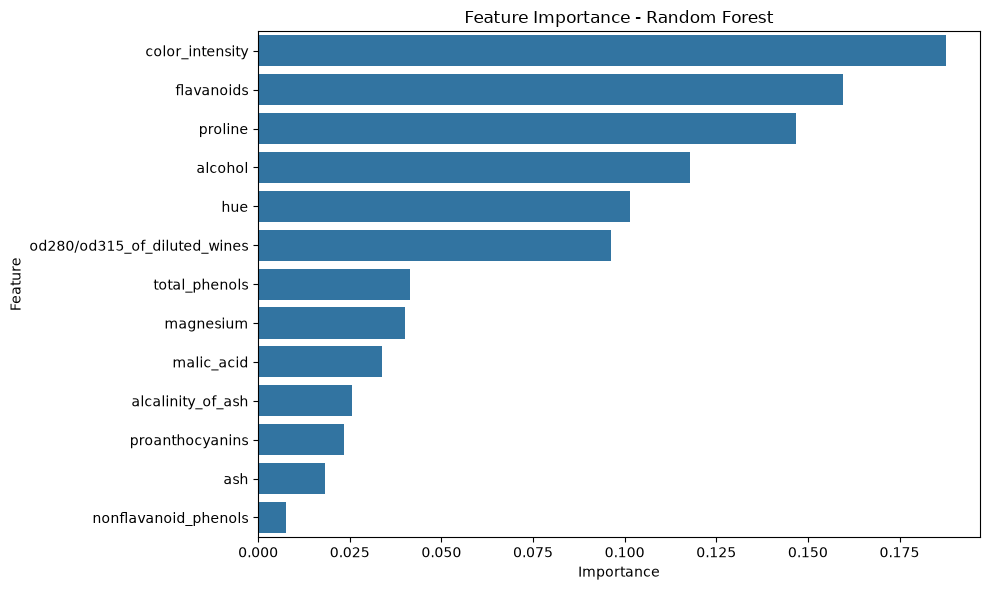

Explained variance ratio: [0.35792104 0.19270671]
Total variance explained: 55.06 %
Linear Regression with PCA: 0.8889
Decision Tree with PCA: 0.8889
Random Forest with PCA: 0.8889


In [ ]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score



# Main analysis function
def main():
    # --- 1. Load data ---
    wine = load_wine()
    df = pd.DataFrame(wine.data, columns = wine.feature_names)
    
    # --- 1.1 Add target cumn ---
    df["target"] = wine.target                                         
    
    # --- 1.2 First output ---
    print("Shape:", df.shape)
    print("Info:", df.info())
    print("First 10 rows:\n", df.head(10)) 
    
    # --- 1.3 Basic summary statistics
    print("\nValue counts:\n", df["target"].value_counts())
    print("\nMaximum:", df["target"].max())
    print("Minimum:", df["target"].min())
    print("\nSummary statistics:\n", df.describe())
    print("\n5 largest rows:\n", df.nlargest(5, "target"))
    print("\n5 smallest rows:\n", df.nsmallest(5, "target"))
    print("\nUnique values:", df["target"].nunique())
    
    
    # --- 2. Basic exploration --- 
    # --- 2.1 Number of samples in each class
    print("Class distribution:\n", df["target"].value_counts())
    
    # --- 2.2 Check for missing values and duplicates ---
    print("Missing values per column:\n", df.isnull().sum())
    print("Number of duplicate rows:", df.duplicated().sum())
    
    
    # --- 3. Visualization ---
    # --- 3.1 Pairplot ---
    selected_features = ["alcohol",
                         "malic_acid",
                         "ash",
                         "magnesium",
                         "color_intensity",
                         "target"]
    
    pair_plot = sns.pairplot(df[selected_features], hue="target", diag_kind='hist')
    plt.suptitle('Pairplot of selected features', y=1.02)
    pair_plot.savefig("wine_pairplot.png", dpi=300, bbox_inches="tight")
    plt.close(pair_plot.figure)
    print("Pairplot saved as wine_pairplot.png")
    
    # --- 3.2 Boxplot ---
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="target", y="alcohol")
    plt.title("Alcohol content across wine classes")
    plt.xlabel("Wine classes")
    plt.ylabel ("Alcohol content")
    plt.tight_layout()
    plt.savefig("wine_boxplot.png", dpi=300, bbox_inches="tight")
    plt.close()
    print("Boxplot saved as wine_boxplot.png")
    
    # --- 3.3 Correlation heatmap ---
    plt.figure(figsize=(8, 6))
    sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap')
    plt.savefig("Correlation heatmap.png", dpi=300, bbox_inches="tight")
    plt.close()
    print("Pairplot saved as Correlation heatmap.png")
    
    
    # --- 4. Scaling and PCA ---
    # --- 4.1 Standardise numerical features ---
    X = df.drop(columns="target")
    y = df["target"]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
    print("Standardised features:", X_scaled_df.head())

    # --- 4.2 PCA ---
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=X.index)
    pca_df["target"] = y
    print("PCA results:", pca_df.head())
    
    sns.scatterplot(data= pca_df, x="PC1", y="PC2", hue="target", palette="Set1", s=80)
    plt.title("PCA Visualization")
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
    plt.legend(title = "Wine class")
    plt.tight_layout()
    plt.savefig("wine_pca_scatterplot.png", dpi=300, bbox_inches="tight")
    plt.close()
    print("PCA scatterplot saved as wine_pca_scatterplot.png")
    

    
    # --- 5. Classification models ---
    # --- 5.1 Linear regression, dedcision tree & random forest
    X = df.drop(columns="target")
    y = df["target"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
    X_test_scaled_df = pd.DataFrame(X_test_scaled,  columns=X.columns, index=X_test.index)

    linear_model = LinearRegression()
    tree_model = DecisionTreeClassifier(random_state=42)
    forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
    
    linear_model.fit(X_train_scaled_df, y_train)
    tree_model.fit(X_train_scaled_df, y_train)
    forest_model.fit(X_train_scaled_df, y_train)

    linear_predictions = linear_model.predict(X_test_scaled_df)
    linear_predictions = linear_predictions.round().clip(0, 2).astype(int)
    tree_predictions = tree_model.predict(X_test_scaled_df)
    forest_predictions = forest_model.predict(X_test_scaled_df)
    
    linear_accuracy = accuracy_score(y_test, linear_predictions)
    tree_accuracy = accuracy_score(y_test, tree_predictions)
    forest_accuracy = accuracy_score(y_test, forest_predictions)

    print("Linear Regression accuracy:", round(linear_accuracy, 4))
    print("Decision Tree accuracy:", round(tree_accuracy, 4))
    print("Random Forest accuracy:", round(forest_accuracy, 4))
    
    
    # --- 5.2 Feature importance ---
    # --- 5.2.1 Decision tree feature importance --- 
    tree_importance = pd.DataFrame({"Feature": X.columns, "Importance": tree_model.feature_importances_})
    tree_importance = tree_importance.sort_values(by="Importance", ascending=False)
    print(tree_importance)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=tree_importance, x="Importance",y="Feature")
    plt.title("Feature Importance - Decision Tree")
    plt.tight_layout()
    plt.savefig("decision_tree_feature_importance.png", dpi=300)
    plt.show()
    
    # --- 5.2.2 Random forest feature importance --- 
    forest_importance = pd.DataFrame({"Feature": X.columns, "Importance": forest_model.feature_importances_})
    forest_importance = forest_importance.sort_values(by="Importance", ascending=False)
    print(forest_importance)
    
    plt.figure(figsize=(10, 6))   
    sns.barplot(data=forest_importance, x="Importance", y="Feature")
    plt.title("Feature Importance - Random Forest")
    plt.tight_layout()
    plt.savefig("random_forest_feature_importance.png", dpi=300)
    plt.show()
    
    # --- 5.3 Comparison model accuracy ---
    # --- 5.3.1 PCA with two components ---
    pca = PCA(n_components=2)
    X_train_pca = pca.fit_transform(X_train_scaled_df)
    X_test_pca = pca.transform(X_test_scaled_df)
    X_train_pca_df = pd.DataFrame(X_train_pca, columns=["PC1", "PC2"], index=X_train.index)
    X_test_pca_df = pd.DataFrame(X_test_pca, columns=["PC1", "PC2"], index=X_test.index)
    print("Explained variance ratio:", pca.explained_variance_ratio_)
    print("Total variance explained:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


    # --- 5.3.2 Rerun models with PCA features ---
    # Create new models
    linear_pca_model = LinearRegression()
    tree_pca_model = DecisionTreeClassifier(random_state=42)
    forest_pca_model = RandomForestClassifier(n_estimators=100, random_state=42)

    # Train using the PCA training data
    linear_pca_model.fit(X_train_pca_df, y_train)
    tree_pca_model.fit(X_train_pca_df, y_train)
    forest_pca_model.fit(X_train_pca_df, y_train)
    
    linear_pca_predictions = linear_pca_model.predict(X_test_pca_df)
    linear_pca_predictions = (linear_pca_predictions.round().clip(0, 2).astype(int))
    
    tree_pca_predictions = tree_pca_model.predict(X_test_pca_df)
    forest_pca_predictions = forest_pca_model.predict(X_test_pca_df)
    
    linear_pca_accuracy = accuracy_score(y_test, linear_pca_predictions)

    tree_pca_accuracy = accuracy_score(y_test, tree_pca_predictions)

    forest_pca_accuracy = accuracy_score(y_test, forest_pca_predictions)

    print("Linear Regression with PCA:", round(linear_pca_accuracy, 4))
    print("Decision Tree with PCA:", round(tree_pca_accuracy, 4))
    print("Random Forest with PCA:", round(forest_pca_accuracy, 4))
    
    

main()    

    
   
    
  